# **Soal UTS — Graf Sains Data**

| | |
|---|---|
| **Nama** | Kharisma Adhi Wibowo |
| **NIM** | 23031554175 |
| **Mata kuliah** | Graf Sains Data (3 SKS) |
| **Prodi** | S1 Sains Data, FMIPA, Universitas Negeri Surabaya |
| **Dataset** | RetailRocket e-commerce (`events.csv`) |

## **1. Tugas Pendahuluan**

### **1.1 Konfigurasi Lingkungan dan Lokasi Data**

In [8]:
import os
import sys
import pandas as pd

from neo4j import GraphDatabase
from tqdm.auto import tqdm

# Lokasi file events.csv
SOURCE_DIR = "data"
CSV_FILE_PATH = os.path.join(SOURCE_DIR, "events.csv")

# Konfigurasi koneksi Neo4j
BOLT_URI = "bolt://localhost:7687"
DB_USER = "neo4j"
DB_PASSWORD = "12345678"
DATABASE = "neo4j"

# Jumlah baris yang diproses setiap batch
BATCH_SIZE = 10_000

print("Konfigurasi selesai.")
print("Lokasi CSV:", CSV_FILE_PATH)
print("Database:", DATABASE)
print("Batch size:", BATCH_SIZE)

Konfigurasi selesai.
Lokasi CSV: data\events.csv
Database: neo4j
Batch size: 10000


**Penjelasan hasil**

Sel ini hanya menyiapkan konfigurasi, sehingga hasilnya berupa ringkasan pengaturan:

- Dataset dibaca dari `data\events.csv`.
- Koneksi memakai Bolt `bolt://localhost:7687` ke database `neo4j`.
- Data diproses per *batch* sebesar **10.000 baris** agar memori dan transaksi Neo4j tetap ringan.

### **1.2 Mempelajari Penggunaan Driver Neo4j**

In [9]:
if not os.path.exists(CSV_FILE_PATH):
    raise FileNotFoundError(
        f"File '{CSV_FILE_PATH}' tidak ditemukan. "
        "Pastikan events.csv berada di folder data."
    )

print("File events.csv ditemukan.")

# Membaca beberapa baris untuk memeriksa struktur data
preview_df = pd.read_csv(CSV_FILE_PATH, nrows=5)

print("\nKolom dataset:")
print(preview_df.columns.tolist())

print("\nContoh data:")
display(preview_df)

File events.csv ditemukan.

Kolom dataset:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Contoh data:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


**Penjelasan hasil**

- File `events.csv` ditemukan, sehingga pemeriksaan keberadaan berkas (`os.path.exists`) lolos.
- Dataset memiliki **5 kolom**: `timestamp` (waktu dalam Unix epoch milidetik), `visitorid` (ID pengunjung), `event` (`view`, `addtocart`, `transaction`), `itemid` (ID produk), dan `transactionid` (hanya terisi saat event `transaction`).
- Lima baris contoh seluruhnya bertipe `view`, sehingga `transactionid` bernilai `NaN`. Nilai kosong ini ditangani pada tahap impor.

In [12]:
def print_friends(driver, name):
    query = (
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name"
    )
    driver = None

try:
    driver = GraphDatabase.driver(
        BOLT_URI,
        auth=(DB_USER, DB_PASSWORD)
    )

    driver.verify_connectivity()

    with driver.session(database=DATABASE) as session:
        result = session.run("RETURN 1 AS status")
        print("Hasil tes query:", result.single()["status"])

    print("Koneksi ke Neo4j berhasil.")

except Exception as e:
    if driver is not None:
        driver.close()

    driver = None
    raise RuntimeError(
        "Koneksi Neo4j gagal. Periksa status DBMS, "
        "alamat Bolt, username, dan password."
    ) from e
    


Hasil tes query: 1
Koneksi ke Neo4j berhasil.


C:\Users\hp\AppData\Local\Temp\ipykernel_18224\2369816495.py:14: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


**Penjelasan hasil**

Driver Neo4j berhasil dibuat dan `verify_connectivity()` lolos. Query uji `RETURN 1 AS status` mengembalikan **1**, yang berarti DBMS aktif dan kredensial benar. Objek `driver` ini dipakai ulang pada seluruh sel berikutnya.

In [13]:
with driver.session(database=DATABASE) as session:

    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """).consume()

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """).consume()

print("Constraint Visitor dan Item berhasil dibuat.")

Constraint Visitor dan Item berhasil dibuat.


**Penjelasan hasil**

Sel ini membuat dua *uniqueness constraint*:

- `visitor_id_unique` pada `(:Visitor {visitorId})`
- `item_id_unique` pada `(:Item {itemId})`

Constraint menjamin satu `visitorId` atau `itemId` hanya menjadi satu simpul, dan Neo4j otomatis membuat indeks sehingga perintah `MERGE` saat impor mencari simpul dengan cepat. Perintah `IF NOT EXISTS` membuat sel aman dijalankan berulang kali.

#### **Pertanyaan Pendahuluan (Checkpoint)**

> 1. Apa nama database yang digunakan pada tutorial ini?
> 2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!
> 3. Apa jenis graf pertemanan yang telah dibuat di sini?

1. Nama Database: neo4j.   
2. Akses ke Database Lain: Menggunakan klausa USE <nama_database> dalam perintah Cypher.   
3. Jenis Graf Pertemanan: Directed Graph (Graf Berarah), ditandai oleh relasi (a)-[:KNOWS]->(friend).   

### **1.3 Impor Data RetailRocket ke Neo4j**

In [14]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {
            timestamp: row.timestamp
        }]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {
            timestamp: row.timestamp
        }]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    }
    """

    tx.run(cypher_query, batch=batch).consume()

**Penjelasan hasil**

Sel ini hanya mendefinisikan fungsi `import_batch`, sehingga tidak ada keluaran. Query Cypher di dalamnya bekerja sebagai berikut:

- `UNWIND $batch AS row` mengubah daftar baris dalam satu *batch* menjadi baris-baris yang diproses satu per satu.
- `MERGE (v:Visitor {visitorId: row.visitorid})` dan `MERGE (i:Item {itemId: row.itemid})` membuat simpul hanya jika belum ada, sehingga tidak terjadi duplikasi simpul.
- `CALL { ... UNION ALL ... }` memilih jenis relasi berdasarkan kolom `event`: `view` menjadi `VIEWED`, `addtocart` menjadi `ADDED_TO_CART`, dan `transaction` menjadi `BOUGHT` (membawa properti `transactionId`).
- Relasi dibuat dengan `CREATE` dan membawa properti `timestamp`, sehingga satu baris data menjadi tepat satu relasi. Karena memakai `CREATE`, menjalankan impor berulang pada database yang belum di-reset akan menggandakan relasi.

In [15]:
if not os.path.exists(CSV_FILE_PATH):
    raise FileNotFoundError(CSV_FILE_PATH)

# Menghitung jumlah baris data untuk progress bar
total_rows = sum(
    len(chunk)
    for chunk in pd.read_csv(
        CSV_FILE_PATH,
        chunksize=BATCH_SIZE
    )
)

total_chunks = (total_rows + BATCH_SIZE - 1) // BATCH_SIZE

print("Total baris data:", total_rows)
print("Total batch:", total_chunks)
print("Memulai proses impor ke Neo4j...")

try:
    with driver.session(database=DATABASE) as session:

        chunks = pd.read_csv(
            CSV_FILE_PATH,
            chunksize=BATCH_SIZE
        )

        for chunk in tqdm(
            chunks,
            total=total_chunks,
            desc="Mengimpor batch"
        ):
            # Membersihkan transactionid kosong/NaN
            chunk["transactionid"] = (
                chunk["transactionid"]
                .fillna("")
                .astype(str)
            )

            # Menghapus baris dengan ID atau event yang tidak valid
            chunk = chunk.dropna(
                subset=[
                    "timestamp",
                    "visitorid",
                    "itemid",
                    "event"
                ]
            )

            # Memastikan ID dan timestamp menjadi integer Python
            for col in ["timestamp", "visitorid", "itemid"]:
                chunk[col] = pd.to_numeric(
                    chunk[col], errors="coerce"
                )

            chunk = chunk.dropna(
                subset=["timestamp", "visitorid", "itemid"]
            )

            chunk = chunk[
                chunk["event"].isin(
                    ["view", "addtocart", "transaction"]
                )
            ]

            for col in ["timestamp", "visitorid", "itemid"]:
                chunk[col] = chunk[col].astype("int64")

            # Konversi nilai NumPy menjadi tipe Python biasa
            records = chunk.to_dict(orient="records")

            for row in records:
                row["timestamp"] = int(row["timestamp"])
                row["visitorid"] = int(row["visitorid"])
                row["itemid"] = int(row["itemid"])
                row["event"] = str(row["event"])
                row["transactionid"] = str(
                    row["transactionid"]
                )

            if records:
                # Kompatibilitas driver Neo4j 4.x dan 5.x
                if hasattr(session, "execute_write"):
                    session.execute_write(import_batch, records)
                else:
                    session.write_transaction(import_batch, records)

    print("\nProses impor selesai.")

except Exception as e:
    print("Terjadi kesalahan ketika mengimpor data:")
    print(e)
    raise

Total baris data: 2756101
Total batch: 276
Memulai proses impor ke Neo4j...


Mengimpor batch:   0%|          | 0/276 [00:00<?, ?it/s]C:\Users\hp\AppData\Local\Temp\ipykernel_18224\249098657.py:35: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  .fillna("")
Mengimpor batch:   0%|          | 1/276 [00:07<33:25,  7.29s/it]C:\Users\hp\AppData\Local\Temp\ipykernel_18224\249098657.py:35: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  .fillna("")
Mengimpor batch:   1%|          | 2/276 [00:08<18:07,  3.97s/it]C:\Users\hp\AppData\Local\Temp\ipykernel_18224\249098657.py:35: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.


Proses impor selesai.


**Penjelasan hasil**

- Total data **2.756.101 baris** yang dibagi menjadi **276 batch** (`ceil(2.756.101 / 10.000)`). Proses berakhir dengan pesan `Proses impor selesai`.
- Sebelum dikirim ke Neo4j, setiap batch dibersihkan: `transactionid` kosong diganti string kosong, baris dengan nilai wajib yang hilang dibuang, dan `timestamp`, `visitorid`, `itemid` dipastikan bertipe integer Python.
- Pesan `Pandas4Warning: 'str' is not supported as a fill value for float64 dtype` adalah **peringatan** dari pandas karena kolom `transactionid` bertipe angka (float) diisi string kosong. Ini bukan galat dan impor tetap selesai.

In [16]:
with driver.session(database=DATABASE) as session:

    node_result = session.run("""
        MATCH (n)
        RETURN labels(n) AS label, count(n) AS total
    """)

    node_summary = [
        record.data() for record in node_result
    ]

    relationship_result = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relasi, count(r) AS total
        ORDER BY jenis_relasi
    """)

    relationship_summary = [
        record.data() for record in relationship_result
    ]

print("=== Jumlah Node ===")
display(pd.DataFrame(node_summary))

print("=== Jumlah Relasi ===")
display(pd.DataFrame(relationship_summary))

# Contoh interaksi yang tersimpan
with driver.session(database=DATABASE) as session:
    sample_result = session.run("""
        MATCH (v:Visitor)-[r]->(i:Item)
        RETURN
            v.visitorId AS visitorId,
            type(r) AS event,
            i.itemId AS itemId,
            r.timestamp AS timestamp
        LIMIT 10
    """)

    sample_rows = [
        record.data() for record in sample_result
    ]

print("=== Contoh Interaksi ===")
display(pd.DataFrame(sample_rows))

=== Jumlah Node ===


,label,total
0,[Person],4
1,[Visitor],1407580
2,[Item],235061


=== Jumlah Relasi ===


,jenis_relasi,total
0,ADDED_TO_CART,207996
1,BOUGHT,67371
2,KNOWS,3
3,SIMILAR_TO,5
4,VIEWED,7992936


=== Contoh Interaksi ===


,visitorId,event,itemId,timestamp
0,257597,VIEWED,355908,1433221332117
1,257597,VIEWED,355908,1433221332117
2,257597,VIEWED,355908,1433221332117
3,981382,VIEWED,355908,1433191365316
4,981382,VIEWED,355908,1433191365316
5,981382,VIEWED,355908,1433191365316
6,1102250,VIEWED,355908,1431414462161
7,1102250,VIEWED,355908,1431414462161
8,1102250,VIEWED,355908,1431414462161
9,62710,VIEWED,355908,1436563183622


**Penjelasan hasil**

- Simpul: **1.407.580 `Visitor`** dan **235.061 `Item`**. Empat simpul `Person` berasal dari latihan tutorial 1.2 (Arthur, Guinevere, Lancelot, Merlin) dengan 3 relasi `KNOWS`.
- Relasi interaksi pada keluaran ini: `VIEWED` 7.992.936, `ADDED_TO_CART` 207.996, dan `BOUGHT` 67.371, total **8.268.303**. Angka ini **tepat tiga kali** jumlah baris `events.csv` (2.756.101), yaitu 3 × 2.664.312 `view`, 3 × 69.332 `addtocart`, dan 3 × 22.457 `transaction`. Artinya impor sudah dijalankan **tiga kali** pada database yang sama.
- Jumlah simpul tidak ikut berlipat karena impor memakai `MERGE` dan constraint unik, sedangkan relasi dibuat dengan `CREATE` sehingga menumpuk setiap kali impor diulang.
- Terdapat 5 relasi `SIMILAR_TO` yang berasal dari proses nomor 7(b) sebelumnya.
- Contoh interaksi memperlihatkan baris yang sama muncul tiga kali berturut-turut (misalnya visitor 257597 ke item 355908), sesuai penjelasan di atas.
- Jika database dikosongkan lalu diimpor sekali saja, jumlah relasi interaksi menjadi 2.756.101.

### **1.4 Impor Library dan Pembacaan Dataset**

In [23]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random
import os

from neo4j import GraphDatabase
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

# Koneksi Neo4j
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "12345678")
DATABASE = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

print("Koneksi Neo4j berhasil!")

# Lokasi dataset
DATA_PATH = "data/events.csv"

# Seed agar pemilihan data acak dapat direproduksi
random.seed(42)
np.random.seed(42)

C:\Users\hp\AppData\Local\Temp\ipykernel_18224\1613933622.py:18: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Koneksi Neo4j berhasil!


**Penjelasan hasil**

Library analisis (NetworkX, SciPy sparse, scikit-learn) dimuat dan koneksi Neo4j berhasil (`Koneksi Neo4j berhasil!`). `random.seed(42)` dan `np.random.seed(42)` ditetapkan agar seluruh pemilihan acak dapat **direproduksi**. `ExperimentalWarning` dari `verify_connectivity()` hanya pemberitahuan bahwa konfigurasi tersebut dapat berubah pada versi driver mendatang, bukan galat.

In [24]:
df = pd.read_csv(CSV_FILE_PATH)

print("Ukuran dataset:", df.shape)
print("Kolom:", df.columns.tolist())

# Pastikan kolom yang dibutuhkan tersedia
required_columns = [
    "timestamp", "visitorid", "event", "itemid", "transactionid"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Kolom tidak ditemukan: {missing_columns}")

# Timestamp RetailRocket menggunakan Unix timestamp dalam milidetik
df["datetime"] = pd.to_datetime(
    df["timestamp"], unit="ms", errors="coerce", utc=True
)

print("Tanggal paling awal :", df["datetime"].min())
print("Tanggal paling akhir:", df["datetime"].max())

display(df.head())

Ukuran dataset: (2756101, 5)
Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']
Tanggal paling awal : 2015-05-03 03:00:04.384000+00:00
Tanggal paling akhir: 2015-09-18 02:59:47.788000+00:00


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117+00:00
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164+00:00
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827+00:00
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914+00:00
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106+00:00


**Penjelasan hasil**

- Dataset berisi **2.756.101 baris × 5 kolom** dan semua kolom wajib tersedia.
- Kolom `timestamp` berupa Unix epoch **milidetik**, jadi dikonversi dengan `unit="ms"` ke kolom `datetime` (UTC) agar terbaca manusia.
- Rentang data: **3 Mei 2015 03:00 s.d. 18 September 2015 02:59 UTC** (sekitar 4,5 bulan). Rentang ini menjadi acuan pemilihan periode P1 dan P2 pada nomor 1.

## **2.1 Wrangling dan EDA**

### **No. 1: Penentuan dua periode waktu**

> Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa tidak boleh sama! (akan ditentukan)
> Misal: Fold training (P1) → 01/2023 - 03/2023; Fold testing (P2) 01/2024 - 06/2024.

In [41]:
P1_START = "2015-05-21"
P1_END   = "2015-08-09"

P2_START = "2015-08-10"
P2_END   = "2015-08-30"

def date_to_ms(date_string):
    """Mengubah tanggal UTC menjadi Unix timestamp milidetik."""
    return int(
        pd.Timestamp(date_string, tz="UTC").timestamp() * 1000
    )

# Batas akhir dibuat eksklusif agar seluruh hari akhir ikut dihitung
P1_START_MS = date_to_ms(P1_START)
P1_END_MS = date_to_ms(
    (pd.Timestamp(P1_END) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
)

P2_START_MS = date_to_ms(P2_START)
P2_END_MS = date_to_ms(
    (pd.Timestamp(P2_END) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
)

print(f"P1 training: {P1_START} s.d. {P1_END}")
print(f"P2 testing : {P2_START} s.d. {P2_END}")

# Memastikan rentang tanggal tidak tumpang tindih
assert P1_END_MS <= P2_START_MS, "Periode P1 dan P2 bertumpang tindih."

P1 training: 2015-05-21 s.d. 2015-08-09
P2 testing : 2015-08-10 s.d. 2015-08-30


**Penjelasan hasil**

- **P1 (training):** 21 Mei 2015 s.d. 9 Agustus 2015 (81 hari). **P2 (testing):** 10 Agustus 2015 s.d. 30 Agustus 2015 (21 hari). Tanggal akhir pada kedua periode dihitung inklusif, dan keduanya berada di dalam rentang data (3 Mei s.d. 18 September 2015).
- P2 dimulai **tepat sehari setelah** P1 berakhir, sehingga tidak ada jeda dan tidak ada tumpang tindih. Urutan waktunya benar: model belajar dari masa lalu dan diuji pada masa depan, tanpa kebocoran data (*data leakage*). `assert` memeriksa bahwa P1 tidak melewati awal P2, dan sel berjalan tanpa galat.
- Batas akhir diubah menjadi **eksklusif** dengan menambahkan satu hari, sehingga seluruh interaksi pada tanggal akhir (9 dan 30 Agustus) ikut terambil.
- Periode testing (21 hari) lebih pendek daripada periode training (81 hari), sehingga jumlah interaksi P2 jauh lebih sedikit dari P1.
- Periode ini sesuai arahan dosen. Seluruh hasil di bawah ini memakai periode tersebut.

### **No. 2: Penerapan filter dan penyimpanan ke CSV**

> Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [42]:
# Membersihkan kolom timestamp
df["timestamp"] = pd.to_numeric(df["timestamp"], errors="coerce")
df = df.dropna(subset=["timestamp", "visitorid", "itemid", "event"]).copy()
df["timestamp"] = df["timestamp"].astype("int64")

# Filter periode training dan testing
train_df = df[
    (df["timestamp"] >= P1_START_MS) &
    (df["timestamp"] < P1_END_MS)
].copy()

test_df = df[
    (df["timestamp"] >= P2_START_MS) &
    (df["timestamp"] < P2_END_MS)
].copy()

# Simpan hasil filter
os.makedirs("data/processed", exist_ok=True)

train_df.to_csv(
    "data/processed/events_P1_training.csv", index=False
)
test_df.to_csv(
    "data/processed/events_P2_testing.csv", index=False
)

print("Jumlah interaksi P1:", len(train_df))
print("Jumlah interaksi P2:", len(test_df))

print("\nDistribusi event P1:")
display(train_df["event"].value_counts().to_frame("jumlah"))

print("\nDistribusi event P2:")
display(test_df["event"].value_counts().to_frame("jumlah"))

print("\nFile berhasil disimpan di folder data/processed/")

Jumlah interaksi P1: 1685829
Jumlah interaksi P2: 375497

Distribusi event P1:


,jumlah
event,
view,1630119
addtocart,41967
transaction,13743



Distribusi event P2:


,jumlah
event,
view,362224
addtocart,10073
transaction,3200



File berhasil disimpan di folder data/processed/


**Penjelasan hasil**

| Periode | Total interaksi | `view` | `addtocart` | `transaction` |
|---|---:|---:|---:|---:|
| P1 (training) | 1.685.829 | 1.630.119 (96,7%) | 41.967 (2,5%) | 13.743 (0,8%) |
| P2 (testing) | 375.497 | 362.224 (96,5%) | 10.073 (2,7%) | 3.200 (0,9%) |

- Filter memakai `timestamp` milidetik dengan batas awal inklusif dan batas akhir eksklusif, sehingga tanggal akhir tercakup seluruhnya.
- Hasil disimpan sebagai `data/processed/events_P1_training.csv` dan `data/processed/events_P2_testing.csv`.
- Komposisi kedua periode hampir sama: `view` sekitar 96,5 sampai 96,7%, `addtocart` sekitar 2,5 sampai 2,7%, dan `transaction` sekitar 0,8 sampai 0,9%. Distribusi yang stabil membuat perbandingan training dan testing lebih adil, walaupun P2 jauh lebih kecil karena periodenya hanya 21 hari.
- Total P1 + P2 adalah 2.061.326 baris (sekitar 74,8% dari 2.756.101 baris data). Sisanya (694.775 baris, yaitu 3 sampai 20 Mei dan 31 Agustus sampai 18 September 2015) berada di luar kedua periode dan tidak dipakai.

### **No. 3: Komposisi subgraph**

> Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [43]:
query_komposisi = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start_ms
  AND r.timestamp < $end_ms
  AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN
    count(DISTINCT v) AS jumlah_visitor,
    count(DISTINCT i) AS jumlah_item,
    count(r) AS jumlah_relasi
"""

with driver.session(database=DATABASE) as session:
    hasil_komposisi = session.run(
        query_komposisi,
        start_ms=P1_START_MS,
        end_ms=P1_END_MS
    ).single()

print("Komposisi subgraph P1:")
display(pd.DataFrame([dict(hasil_komposisi)]))

Komposisi subgraph P1:


,jumlah_visitor,jumlah_item,jumlah_relasi
0,869046,190107,5057487


**Penjelasan Cypher**

- `MATCH (v:Visitor)-[r]->(i:Item)` mengambil pola Visitor yang berelasi ke Item.
- `WHERE r.timestamp >= $start_ms AND r.timestamp < $end_ms` membatasi relasi pada P1. Nilai batas dikirim sebagai parameter (`$start_ms`, `$end_ms`) melalui Python API (`session.run(query, start_ms=..., end_ms=...)`).
- `type(r) IN [...]` hanya menyertakan relasi interaksi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`) dan mengabaikan `KNOWS` dan `SIMILAR_TO`.
- `count(DISTINCT v)` dan `count(DISTINCT i)` menghitung simpul unik, sedangkan `count(r)` menghitung seluruh relasi yang cocok.

**Penjelasan hasil**

Subgraph P1 terdiri atas **dua jenis simpul**: **869.046 Visitor** dan **190.107 Item**. Jumlah ini sama dengan baris dan kolom VSM P1 pada nomor 4 (869.046 × 190.107), sehingga filter di Neo4j dan di pandas konsisten.

Jumlah relasi yang tampil adalah **5.057.487**, tepat **3 kali** jumlah interaksi P1 di CSV (3 × 1.685.829). Faktor yang sama muncul pada hasil per jenis relasi di sel berikut, karena database memuat tiga salinan setiap interaksi (impor terjalankan tiga kali, lihat bagian 1.3). Jika database di-reset dan diimpor sekali, angkanya menjadi **1.685.829**. Jumlah simpul unik tidak terpengaruh.

In [44]:
query_jenis_relasi = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start_ms
  AND r.timestamp < $end_ms
  AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""

with driver.session(database=DATABASE) as session:
    hasil_relasi = list(session.run(
        query_jenis_relasi,
        start_ms=P1_START_MS,
        end_ms=P1_END_MS
    ))

relasi_df = pd.DataFrame([record.data() for record in hasil_relasi])
display(relasi_df)

,jenis_relasi,jumlah
0,VIEWED,4890357
1,ADDED_TO_CART,125901
2,BOUGHT,41229


**Penjelasan hasil**

Query mengelompokkan relasi menggunakan `type(r)` dan menghitungnya dengan `count(r)`, lalu mengurutkan jumlah secara menurun.

| Jenis relasi | Jumlah pada keluaran Neo4j | Jumlah interaksi P1 di CSV | Rasio |
|---|---:|---:|---:|
| `VIEWED` | 4.890.357 | 1.630.119 | 3 × |
| `ADDED_TO_CART` | 125.901 | 41.967 | 3 × |
| `BOUGHT` | 41.229 | 13.743 | 3 × |

Proporsinya sejalan dengan nomor 2: `VIEWED` paling banyak (sekitar 96,7%) dan `BOUGHT` paling sedikit, sesuai pola corong (*funnel*) e-commerce. Setiap jumlah di Neo4j tepat 3 kali jumlah di CSV, sehingga rasio antarjenis relasi tetap benar walaupun angka mutlaknya menggelembung.

### **No. 4: Vector Space Modelling (VSM) simpul User**

> Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [45]:
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import networkx as nx

# Samakan format ID untuk pengolahan Python
train_df["visitorid"] = train_df["visitorid"].astype(str)
train_df["itemid"] = train_df["itemid"].astype(str)

interaction_df = (
    train_df.groupby(["visitorid", "itemid"])
    .size()
    .reset_index(name="weight")
)

visitor_ids = sorted(interaction_df["visitorid"].unique())
item_ids = sorted(interaction_df["itemid"].unique())

visitor_index = {v: i for i, v in enumerate(visitor_ids)}
item_index = {item: i for i, item in enumerate(item_ids)}

rows = interaction_df["visitorid"].map(visitor_index).to_numpy()
cols = interaction_df["itemid"].map(item_index).to_numpy()
values = interaction_df["weight"].to_numpy(dtype=float)

X = csr_matrix(
    (values, (rows, cols)),
    shape=(len(visitor_ids), len(item_ids))
)

print("Jumlah Visitor:", len(visitor_ids))
print("Jumlah Item:", len(item_ids))
print("Shape VSM Visitor:", X.shape)
print("Jumlah elemen bukan nol:", X.nnz)
print("Kepadatan matriks:", X.nnz / (X.shape[0] * X.shape[1]))

Jumlah Visitor: 869046
Jumlah Item: 190107
Shape VSM Visitor: (869046, 190107)
Jumlah elemen bukan nol: 1312728
Kepadatan matriks: 7.945731314061234e-06


**Penjelasan hasil**

Matriks interaksi **Visitor × Item** (VSM User) dibangun dari data P1. Baris mewakili Visitor, kolom mewakili Item, dan nilai sel adalah jumlah interaksi pada pasangan tersebut (bobot).

- **Shape:** (869.046, 190.107), yaitu 869.046 vektor Visitor, masing-masing berdimensi **190.107** (jumlah Item).
- **Elemen bukan nol:** 1.312.728 pasangan Visitor–Item. Jumlah ini lebih kecil daripada 1.685.829 interaksi karena sekitar 373 ribu interaksi adalah pengulangan pasangan yang sama dan digabung saat matriks dibentuk.
- **Kepadatan:** sekitar 7,9 × 10⁻⁶ (≈ 0,0008%), sehingga matriks sangat *sparse*. Format `csr_matrix` lebih sesuai daripada matriks penuh yang hampir seluruhnya nol.
- **Rata-rata isi per vektor:** 1.312.728 / 869.046 ≈ **1,5 item** per Visitor. Banyak vektor Visitor hanya memuat satu atau dua item, sehingga informasinya sedikit.

Jumlah simpul graf sampel: 100
Jumlah sisi graf sampel: 4237


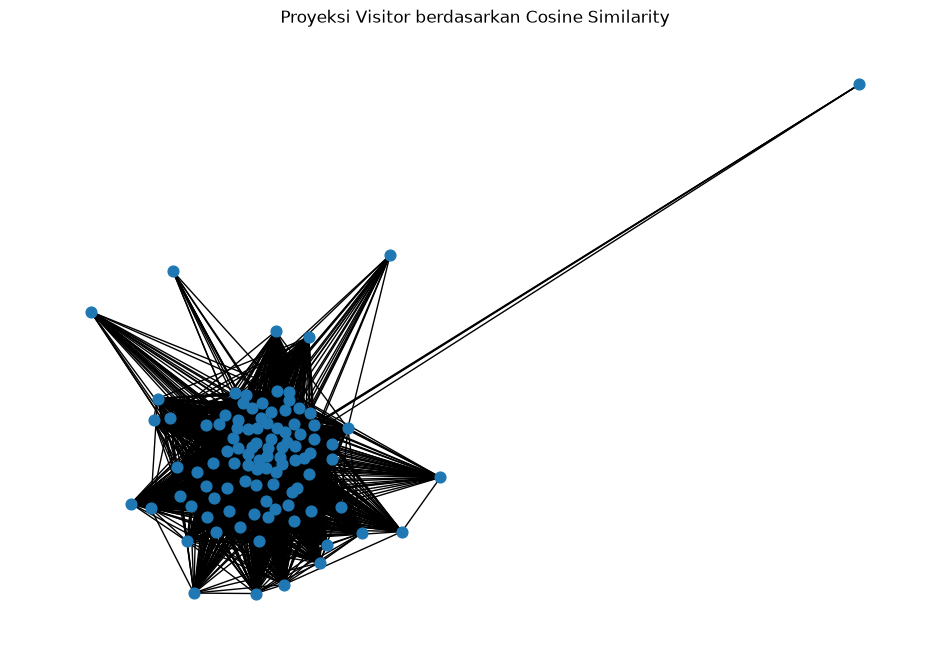

In [46]:
MAX_VISITORS_PLOT = min(100, len(visitor_ids))

visitor_activity = np.asarray(X.sum(axis=1)).ravel()
sample_visitor_idx = np.argsort(visitor_activity)[::-1][:MAX_VISITORS_PLOT]

S_user_sample = cosine_similarity(X[sample_visitor_idx])

G_user = nx.Graph()

for local_idx, global_idx in enumerate(sample_visitor_idx):
    G_user.add_node(visitor_ids[global_idx])

for i in range(len(sample_visitor_idx)):
    for j in range(i + 1, len(sample_visitor_idx)):
        score = S_user_sample[i, j]
        if score > 0:
            G_user.add_edge(
                visitor_ids[sample_visitor_idx[i]],
                visitor_ids[sample_visitor_idx[j]],
                weight=float(score)
            )

print("Jumlah simpul graf sampel:", G_user.number_of_nodes())
print("Jumlah sisi graf sampel:", G_user.number_of_edges())

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_user, seed=42)
nx.draw_networkx(
    G_user, pos,
    with_labels=False,
    node_size=60
)
plt.title("Proyeksi Visitor berdasarkan Cosine Similarity")
plt.axis("off")
plt.show()

**Penjelasan hasil**

Graf dibuat dari **100 Visitor dengan aktivitas tertinggi**, dengan sisi untuk pasangan yang memiliki *cosine similarity* lebih dari nol.

- Sampel graf berisi **100 simpul** dan **4.237 sisi** dari maksimum 4.950 pasangan (100 × 99 / 2), atau sekitar **85,6%** pasangan.
- Visualisasi tampak sangat rapat karena Visitor teraktif banyak menyentuh item populer yang sama, sehingga irisan itemnya besar dan similarity-nya positif.
- Angka ini hanya menggambarkan sampel Visitor teraktif, bukan seluruh 869.046 Visitor. Pada seluruh data graf proyeksi jauh lebih jarang.

### **No. 5: Vector Space Modelling (VSM) simpul Item**

> Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

Shape VSM Item: (190107, 869046)
Jumlah elemen bukan nol: 1312728
Jumlah simpul graf sampel: 100
Jumlah sisi graf sampel: 3063


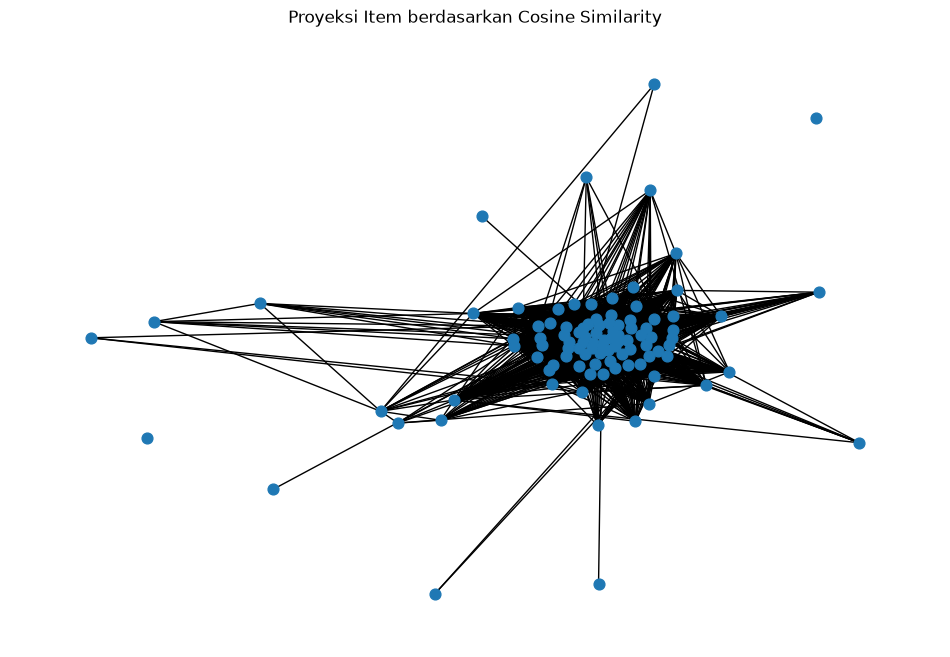

In [47]:
# Transpose: baris Item, kolom Visitor
X_item = X.T.tocsr()

print("Shape VSM Item:", X_item.shape)
print("Jumlah elemen bukan nol:", X_item.nnz)

MAX_ITEMS_PLOT = min(100, len(item_ids))

item_activity = np.asarray(X_item.sum(axis=1)).ravel()
sample_item_idx = np.argsort(item_activity)[::-1][:MAX_ITEMS_PLOT]

S_item_sample = cosine_similarity(X_item[sample_item_idx])

G_item = nx.Graph()

for global_idx in sample_item_idx:
    G_item.add_node(item_ids[global_idx])

for i in range(len(sample_item_idx)):
    for j in range(i + 1, len(sample_item_idx)):
        score = S_item_sample[i, j]
        if score > 0:
            G_item.add_edge(
                item_ids[sample_item_idx[i]],
                item_ids[sample_item_idx[j]],
                weight=float(score)
            )

print("Jumlah simpul graf sampel:", G_item.number_of_nodes())
print("Jumlah sisi graf sampel:", G_item.number_of_edges())

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_item, seed=42)
nx.draw_networkx(
    G_item, pos,
    with_labels=False,
    node_size=60
)
plt.title("Proyeksi Item berdasarkan Cosine Similarity")
plt.axis("off")
plt.show()

**Penjelasan hasil**

VSM Item adalah **transpose** matriks Visitor × Item, sehingga baris mewakili Item dan kolom mewakili Visitor.

- **Shape:** (190.107, 869.046), yaitu 190.107 vektor Item, masing-masing berdimensi **869.046** (jumlah Visitor).
- **Elemen bukan nol:** 1.312.728, sama dengan VSM User karena transpose tidak mengubah isi matriks.
- **Rata-rata isi per vektor:** 1.312.728 / 190.107 ≈ **6,9 visitor** per item, jauh lebih terisi daripada VSM User (≈ 1,5 item per visitor).
- **Graf sampel** dari 100 Item teraktif memiliki **100 simpul** dan **3.063 sisi**, sekitar **61,9%** dari 4.950 pasangan maksimum. Seperti graf Visitor, angka ini hanya berlaku untuk sampel Item teraktif.

### **No. 6: Perbandingan proyeksi (efektif/efisien)**

> Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

In [48]:
comparison_df = pd.DataFrame([
    {
        "Proyeksi": "Visitor",
        "Jumlah simpul VSM": X.shape[0],
        "Jumlah fitur": X.shape[1],
        "Elemen bukan nol": X.nnz,
        "Simpul graf sampel": G_user.number_of_nodes(),
        "Sisi graf sampel": G_user.number_of_edges()
    },
    {
        "Proyeksi": "Item",
        "Jumlah simpul VSM": X_item.shape[0],
        "Jumlah fitur": X_item.shape[1],
        "Elemen bukan nol": X_item.nnz,
        "Simpul graf sampel": G_item.number_of_nodes(),
        "Sisi graf sampel": G_item.number_of_edges()
    }
])

display(comparison_df)

,Proyeksi,Jumlah simpul VSM,Jumlah fitur,Elemen bukan nol,Simpul graf sampel,Sisi graf sampel
0,Visitor,869046,190107,1312728,100,4237
1,Item,190107,869046,1312728,100,3063


**Penjelasan hasil**

| Aspek | Proyeksi Visitor | Proyeksi Item |
|---|---:|---:|
| Jumlah simpul/vektor | 869.046 | 190.107 |
| Dimensi vektor | 190.107 | 869.046 |
| Elemen bukan nol | 1.312.728 | 1.312.728 |
| Rata-rata isi per vektor | ≈ 1,5 | ≈ 6,9 |
| Sisi pada graf sampel (100 simpul teraktif) | 4.237 | 3.063 |
| Perkiraan memori matriks similarity *dense* (float64) | ≈ 6,04 TB | ≈ 289 GB |

**Kesimpulan: proyeksi Item lebih baik, baik dari sisi efisiensi maupun efektivitas.**

- **Efisien.** Jumlah simpul Item sekitar 4,6 kali lebih sedikit. Matriks similarity berukuran n × n, sehingga kebutuhan memorinya sekitar **20,9 kali lebih kecil** (≈ 289 GB berbanding ≈ 6,04 TB). Ini perkiraan jika seluruh matriks *dense* dibentuk, bukan memori matriks VSM yang disimpan sparse.
- **Efektif.** Vektor Item lebih terisi (≈ 6,9 berbanding ≈ 1,5 elemen bukan nol), sehingga *cosine similarity*-nya lebih informatif. Vektor Visitor yang hanya memuat satu atau dua item mudah menghasilkan skor yang seri (pada nomor 7 tiga tetangga seri di 0,228315, dan pada 2.2 kelima tetangga seri di 1,0).
- Item juga lebih stabil: katalog produk relatif tetap, sedangkan Visitor sangat banyak dan sebagian besar hanya muncul sedikit.
- Jumlah sisi pada graf sampel (4.237 untuk Visitor dan 3.063 untuk Item) berasal dari 100 simpul teraktif dan bukan ukuran seluruh proyeksi, sehingga tidak dipakai sebagai dasar penilaian efisiensi.

### **No. 7: Perhitungan similarity dengan Python**

> Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python
> (a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!
> (b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-nya!

In [49]:
anchor_idx = int(np.argmax(visitor_activity))
anchor_visitor = visitor_ids[anchor_idx]

similarity_scores = cosine_similarity(
    X[anchor_idx],
    X
).ravel()

candidate_idx = np.argsort(similarity_scores)[::-1]

top5_idx = [
    idx for idx in candidate_idx
    if idx != anchor_idx and similarity_scores[idx] > 0
][:5]

top5_similarity_df = pd.DataFrame({
    "visitorid": [visitor_ids[idx] for idx in top5_idx],
    "similarity": [float(similarity_scores[idx]) for idx in top5_idx]
})

print("Visitor acuan:", anchor_visitor)
print("Lima Visitor dengan similarity tertinggi:")
display(top5_similarity_df)

Visitor acuan: 1150086
Lima Visitor dengan similarity tertinggi:


,visitorid,similarity
0,530559,0.247523
1,371606,0.240657
2,1150164,0.228315
3,429443,0.228315
4,648525,0.228315


**Penjelasan hasil**

- **Visitor acuan:** **1150086**, yaitu Visitor dengan aktivitas tertinggi (`argmax` total bobot interaksi) pada VSM P1.
- **Metrik:** *cosine similarity* antara vektor acuan dan seluruh vektor Visitor, $\cos(a,b)=\dfrac{a\cdot b}{\|a\|\,\|b\|}$. Acuan sendiri dikeluarkan dan hanya skor positif yang dipertimbangkan.
- **Lima tetangga teratas:** 530559 (0,247523), 371606 (0,240657), serta 1150164, 429443, dan 648525 yang seri di **0,228315**.
- Skor tertinggi hanya sekitar 0,25. Acuan adalah visitor yang sangat aktif dengan vektor panjang, sehingga tetangganya hanya berbagi sebagian kecil item dan nilai cosine-nya relatif rendah.
- Perhitungan memakai vektor Visitor karena soal 2.2 membutuhkan KNN antar-user. Untuk pasangan Item–Item, `X_item` pada nomor 5 dapat dipakai dengan cara yang sama.

### **No. 7(b): Menuliskan similarity ke graf**

In [50]:
records = [
    {
        "visitorid": int(row["visitorid"]),
        "score": float(row["similarity"])
    }
    for _, row in top5_similarity_df.iterrows()
]

query_save_similarity = """
MATCH (source:Visitor {visitorId: $anchor})
UNWIND $records AS rec
MATCH (target:Visitor {visitorId: rec.visitorid})
MERGE (source)-[s:SIMILAR_TO]->(target)
SET s.score = rec.score,
    s.period = $period
RETURN source.visitorId AS visitor_acuan,
       target.visitorId AS visitor_mirip,
       s.score AS similarity,
       s.period AS periode
ORDER BY similarity DESC
"""

with driver.session(database=DATABASE) as session:
    saved_similarity = list(session.run(
        query_save_similarity,
        anchor=int(anchor_visitor),
        records=records,
        period=f"{P1_START} - {P1_END}"
    ))

print("Relasi similarity yang tersimpan:")
display(pd.DataFrame([r.data() for r in saved_similarity]))

Relasi similarity yang tersimpan:


,visitor_acuan,visitor_mirip,similarity,periode
0,1150086,530559,0.247523,2015-05-21 - 2015-08-09
1,1150086,371606,0.240657,2015-05-21 - 2015-08-09
2,1150086,1150164,0.228315,2015-05-21 - 2015-08-09
3,1150086,429443,0.228315,2015-05-21 - 2015-08-09
4,1150086,648525,0.228315,2015-05-21 - 2015-08-09


**Penjelasan hasil**

Skor similarity ditulis ke Neo4j sebagai relasi **`(:Visitor)-[:SIMILAR_TO {score, period}]->(:Visitor)`**.

- `MATCH` mencari Visitor acuan, `UNWIND $records AS rec` memproses lima tetangga, dan `MATCH` berikutnya mencari Visitor tujuan.
- `MERGE` membuat relasi bila belum ada, dan `SET` menyimpan skor serta periode P1.
- Keluaran berisi **5 relasi** dari Visitor **1150086** dengan skor **0,247523; 0,240657; 0,228315; 0,228315; dan 0,228315** serta periode `2015-05-21 - 2015-08-09`. Nilainya sama dengan hasil perhitungan Python pada sel sebelumnya.
- **Catatan:** `MERGE` hanya menambah atau memperbarui relasi, dan tidak menghapus relasi lama. Relasi `SIMILAR_TO` dari proses sebelumnya (periode lama) pada acuan yang sama masih tersimpan di database. Hal ini memengaruhi hasil query 7(a) di bawah.

### **No. 7(a): CYPHER untuk 5 record similarity tertinggi**

In [51]:
query_top5 = """
MATCH (source:Visitor {visitorId: $anchor})
      -[s:SIMILAR_TO]->(target:Visitor)
RETURN source.visitorId AS visitor_acuan,
       target.visitorId AS visitor_mirip,
       s.score AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session(database=DATABASE) as session:
    result_top5 = list(session.run(
        query_top5,
        anchor=int(anchor_visitor)
    ))

display(pd.DataFrame([r.data() for r in result_top5]))

,visitor_acuan,visitor_mirip,similarity
0,1150086,140567,0.256493
1,1150086,761835,0.256493
2,1150086,530559,0.247523
3,1150086,371606,0.240657
4,1150086,429443,0.228315


**Penjelasan hasil**

Query membaca relasi `SIMILAR_TO` yang tersimpan, mengurutkannya berdasarkan `s.score` menurun, lalu mengambil lima teratas.

Keluaran: 140567 dan 761835 (0,256493), 530559 (0,247523), 371606 (0,240657), dan 429443 (0,228315).

**Mengapa tidak sama persis dengan hasil Python?** Visitor 140567 dan 761835 tidak ada pada lima teratas perhitungan P1 saat ini. Keduanya adalah relasi `SIMILAR_TO` sisa dari proses sebelumnya (periode lama) yang masih tersimpan, sehingga ikut terambil karena skornya lebih tinggi. Skor 530559 dan 371606 sudah diperbarui oleh `SET` pada 7(b). Di antara tiga visitor yang seri di 0,228315, query hanya mengembalikan satu (429443) karena dibatasi `LIMIT 5`.

Agar 7(a) hanya memuat hasil periode ini, relasi lama dapat dihapus sebelum 7(b) dengan `MATCH (:Visitor {visitorId: $anchor})-[s:SIMILAR_TO]->() DELETE s`, lalu jalankan ulang 7(b), 7(a), dan nomor 8. Sel ini dijalankan setelah 7(b) karena query membaca relasi yang baru ditulis.

### **No. 8: Kondisi graf sebelum dan sesudah perhitungan similarity**

> Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

In [52]:
query_before = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start_ms
  AND r.timestamp < $end_ms
  AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN v, r, i
LIMIT 50
"""

query_after = """
MATCH (source:Visitor {visitorId: $anchor})
      -[s:SIMILAR_TO]->(target:Visitor)
RETURN source, s, target
ORDER BY s.score DESC
LIMIT 5
"""

with driver.session(database=DATABASE) as session:
    before_result = list(session.run(
        query_before,
        start_ms=P1_START_MS,
        end_ms=P1_END_MS
    ))

    after_result = list(session.run(
        query_after,
        anchor=int(anchor_visitor)
    ))

print("Jumlah contoh interaksi sebelum similarity:", len(before_result))
print("Jumlah relasi similarity setelah proses:", len(after_result))

print("\nContoh sebelum similarity:")
display(pd.DataFrame([
    {
        "visitorid": r["v"]["visitorId"],
        "itemid": r["i"]["itemId"],
        "jenis_relasi": r["r"].type
    }
    for r in before_result
]))

print("\nContoh sesudah similarity:")
display(pd.DataFrame([
    {
        "visitor_acuan": r["source"]["visitorId"],
        "visitor_mirip": r["target"]["visitorId"],
        "similarity": r["s"]["score"]
    }
    for r in after_result
]))

Jumlah contoh interaksi sebelum similarity: 50
Jumlah relasi similarity setelah proses: 5

Contoh sebelum similarity:


,visitorid,itemid,jenis_relasi
0,257597,355908,VIEWED
1,257597,355908,VIEWED
2,257597,355908,VIEWED
3,981382,355908,VIEWED
4,981382,355908,VIEWED
5,981382,355908,VIEWED
6,62710,355908,VIEWED
7,62710,355908,VIEWED
8,62710,355908,VIEWED
9,979686,355908,VIEWED



Contoh sesudah similarity:


,visitor_acuan,visitor_mirip,similarity
0,1150086,140567,0.256493
1,1150086,761835,0.256493
2,1150086,530559,0.247523
3,1150086,371606,0.240657
4,1150086,429443,0.228315


**Penjelasan hasil**

- **Sebelum similarity:** `query_before` mengambil 50 relasi interaksi `(Visitor)-[r]->(Item)` pada periode P1. Seluruh baris yang tampil bertipe `VIEWED` ke item 355908, dan belum ada hubungan antar-Visitor. Setiap pasangan Visitor–Item muncul **tiga kali berturut-turut**, sesuai faktor duplikasi pada komposisi subgraph.
- **Sesudah similarity:** `query_after` mengambil **5 relasi** `SIMILAR_TO` dari Visitor **1150086**, dengan skor **0,228315 sampai 0,256493**. Dua relasi teratas (140567 dan 761835) adalah sisa proses sebelumnya seperti dijelaskan pada 7(a), sehingga daftar ini belum sepenuhnya mencerminkan perhitungan P1 saat ini.
- Perubahan kondisi graf: sebelumnya hanya ada relasi Visitor→Item, sekarang ditambah relasi Visitor→Visitor berlabel `SIMILAR_TO` dengan properti `score`.
- `RETURN v, r, i` dan `RETURN source, s, target` dapat dijalankan di **Neo4j Browser** untuk melihat bentuk graf secara visual.

## **2.2 Analytics**

### **No. 1: User acak dan rekomendasi KNN (k = 5)**

> Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu
> (a) tuliskan skrip Python dalam merekomendasikan KNN-nya!
> (b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

**Pemilihan user acak**

In [53]:
import random

RANDOM_SEED = 42
K = 5

train_visitors = set(train_df["visitorid"].astype(str))
test_visitors = set(test_df["visitorid"].astype(str))

eligible_visitors = sorted(train_visitors & test_visitors)

if not eligible_visitors:
    raise ValueError(
        "Tidak ada Visitor yang muncul di P1 dan P2. "
        "Periksa kembali periode training dan testing."
    )

rng = random.Random(RANDOM_SEED)
selected_visitor = rng.choice(eligible_visitors)

print("Random seed:", RANDOM_SEED)
print("Jumlah Visitor kandidat:", len(eligible_visitors))
print("Visitor terpilih:", selected_visitor)
print("K untuk KNN:", K)

Random seed: 42
Jumlah Visitor kandidat: 16711
Visitor terpilih: 1273232
K untuk KNN: 5


**Penjelasan hasil**

- **Proses acak yang dapat direproduksi:** kandidat diurutkan (`sorted`) lalu dipilih dengan `random.Random(42).choice(...)`. Seed dan urutan kandidat yang sama selalu menghasilkan pilihan yang sama.
- **Kandidat:** Visitor yang muncul di P1 **dan** P2, sehingga punya data latih dan data uji. Jumlahnya **16.711**.
- **Visitor terpilih:** **1273232**, dengan **k = 5** tetangga.

**1(a) Skrip KNN dan 1(b) tiga item yang diiklankan**

In [54]:
selected_idx = visitor_index[selected_visitor]

scores = cosine_similarity(X[selected_idx], X).ravel()

neighbor_order = np.argsort(scores)[::-1]

neighbors = [
    idx for idx in neighbor_order
    if idx != selected_idx and scores[idx] > 0
][:K]

neighbors_df = pd.DataFrame({
    "visitorid": [visitor_ids[idx] for idx in neighbors],
    "similarity": [float(scores[idx]) for idx in neighbors]
})

print("Lima tetangga terdekat:")
display(neighbors_df)

seen_items = set(
    train_df.loc[
        train_df["visitorid"].astype(str) == selected_visitor,
        "itemid"
    ].astype(str)
)

recommendation_scores = {}

for neighbor_idx in neighbors:
    neighbor_vector = X[neighbor_idx].toarray().ravel()

    for item_idx in np.flatnonzero(neighbor_vector):
        item_id = item_ids[item_idx]

        if item_id in seen_items:
            continue

        score = float(scores[neighbor_idx]) * neighbor_vector[item_idx]
        recommendation_scores[item_id] = (
            recommendation_scores.get(item_id, 0.0) + score
        )

ranked_items = sorted(
    recommendation_scores.items(),
    key=lambda x: x[1],
    reverse=True
)

recommendations_df = pd.DataFrame(
    ranked_items[:5],
    columns=["itemid", "recommendation_score"]
)

print("Hasil rekomendasi:")
display(recommendations_df)

print("Tiga Item teratas untuk jawaban 2.2 nomor 1(b):")
display(recommendations_df.head(3))

Lima tetangga terdekat:


,visitorid,similarity
0,646,1.0
1,635326,1.0
2,677312,1.0
3,747153,1.0
4,954497,1.0


Hasil rekomendasi:


,itemid,recommendation_score


Tiga Item teratas untuk jawaban 2.2 nomor 1(b):


,itemid,recommendation_score


**Penjelasan skrip**

1. Hitung *cosine similarity* vektor Visitor terpilih terhadap seluruh Visitor pada VSM P1.
2. Ambil lima tetangga dengan skor positif, tanpa memasukkan Visitor itu sendiri.
3. Beri skor tiap item: $\text{skor}(item)=\sum_{n\in KNN} sim(u,n)\times w_{n,item}$, dengan $w$ adalah bobot interaksi tetangga terhadap item.
4. Buang item yang sudah pernah berinteraksi dengan Visitor target di P1, lalu urutkan sisanya berdasarkan skor.

**Penjelasan hasil**

- Lima tetangga terdekat adalah **646, 635326, 677312, 747153, dan 954497**, masing-masing dengan similarity **1,0**.
- Similarity 1,0 berarti vektor tetangga searah dengan vektor Visitor target, jadi item yang mereka sentuh sama dengan item Visitor target (hanya bobotnya yang bisa berbeda). Karena itu tidak ada item baru untuk direkomendasikan.
- Tabel rekomendasi dan tiga item yang diiklankan **kosong**. Setelah item yang sudah pernah dilihat Visitor target dibuang, tidak ada kandidat tersisa dari kelima tetangga.
- Ini keluaran dari aturan penyaringan pada data yang sangat *sparse* (rata-rata Visitor hanya punya sekitar 1,5 item), bukan galat kode. Jika sistem harus selalu menampilkan rekomendasi, dapat dipakai cadangan berupa item terpopuler atau pendekatan item-based.

### **No. 2: Hit@5 dan NDCG@5**

> Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:
> (a) Hit@5
> (b) NDCG@5

**Ground truth dari periode testing (P2)**

In [55]:
test_selected = test_df[
    test_df["visitorid"].astype(str) == selected_visitor
].copy()

# Ground truth hanya Item yang dikenal oleh VSM training
relevant_items = (
    set(test_selected["itemid"].astype(str))
    & set(item_ids)
)

recommended_items = (
    recommendations_df["itemid"].astype(str).tolist()
)

top5_items = recommended_items[:5]

print("Visitor:", selected_visitor)
print("Jumlah Item relevan di P2:", len(relevant_items))
print("Rekomendasi:", top5_items)
print("Item relevan:", sorted(relevant_items)[:20])

Visitor: 1273232
Jumlah Item relevan di P2: 1
Rekomendasi: []
Item relevan: ['428051']


**Penjelasan hasil**

- *Ground truth* adalah item yang berinteraksi dengan Visitor **1273232** selama P2 dan juga dikenal pada VSM P1 (model tidak mungkin merekomendasikan item yang belum ada saat training).
- Terdapat **1 item relevan**: `428051`.
- Daftar rekomendasi top-5 kosong (`[]`), sebagaimana hasil nomor 1, sehingga item relevan tersebut tidak muncul pada rekomendasi.

**Perhitungan metrik**

In [56]:
# Hit@5: 1 jika ada minimal satu Item relevan di top 5
hit_at_5 = int(
    len(set(top5_items) & relevant_items) > 0
)

# DCG@5: item relevan di posisi lebih tinggi memiliki bobot lebih besar
dcg_at_5 = sum(
    1 / np.log2(rank + 1)
    for rank, item in enumerate(top5_items, start=1)
    if item in relevant_items
)

# DCG ideal
ideal_count = min(len(relevant_items), 5)

idcg_at_5 = sum(
    1 / np.log2(rank + 1)
    for rank in range(1, ideal_count + 1)
)

ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0.0
)

evaluation_df = pd.DataFrame([{
    "visitorid": selected_visitor,
    "k_neighbors": K,
    "jumlah_rekomendasi": len(top5_items),
    "jumlah_item_relevan_P2": len(relevant_items),
    "Hit@5": hit_at_5,
    "NDCG@5": ndcg_at_5
}])

display(evaluation_df)

,visitorid,k_neighbors,jumlah_rekomendasi,jumlah_item_relevan_P2,Hit@5,NDCG@5
0,1273232,5,0,1,0,0.0


**Penjelasan metrik**

- **Hit@5** bernilai 1 jika minimal satu item relevan muncul di lima rekomendasi teratas, selain itu 0.
- **NDCG@5** = DCG@5 / IDCG@5, dengan $DCG@5=\sum_{r=1}^{5}\dfrac{rel_r}{\log_2(r+1)}$. Item relevan di posisi atas diberi bobot lebih besar. Untuk 1 item relevan, IDCG@5 = $1/\log_2 2 = 1$.

**Penjelasan hasil**

| Visitor | k | Jumlah rekomendasi | Item relevan di P2 | Hit@5 | NDCG@5 |
|---|---:|---:|---:|---:|---:|
| 1273232 | 5 | 0 | 1 | **0** | **0,0** |

Tidak ada item yang direkomendasikan, sehingga tidak ada irisan dengan item relevan (`428051`). Karena itu Hit@5 dan NDCG@5 sama-sama **0**. Nilai nol ini mencerminkan hasil KNN nomor 1 yang tidak menghasilkan kandidat, bukan kesalahan rumus.